# Intelligent Web-Based Network Intrusion Detection System Using Machine Learning

## Notebook 05: Saving the Optimized SVM Model

### Objective

This notebook saves the trained machine learning model and preprocessing objects so they can be used later in the web application without retraining.

In [5]:
import numpy as np
import pandas as pd
import joblib

import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    precision_recall_curve
)

from sklearn.model_selection import cross_val_score

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
PROJECT_PATH = "/content/drive/MyDrive/Intelligent_NIDS_Project"

DATASET_PATH = PROJECT_PATH + "/datasets"
MODEL_PATH = PROJECT_PATH + "/models"
RESULTS_PATH = PROJECT_PATH + "/results"

In [8]:
X_train_scaled = joblib.load(DATASET_PATH + "/X_train_scaled.pkl")
X_test_scaled = joblib.load(DATASET_PATH + "/X_test_scaled.pkl")

y_train = joblib.load(DATASET_PATH + "/y_train.pkl")
y_test = joblib.load(DATASET_PATH + "/y_test.pkl")

best_svm = joblib.load(MODEL_PATH + "/best_svm_model.pkl")

print("Everything Loaded Successfully!")

Everything Loaded Successfully!


In [9]:
print("Training Data :", X_train_scaled.shape)
print("Testing Data  :", X_test_scaled.shape)

print("Training Labels :", y_train.shape)
print("Testing Labels  :", y_test.shape)

Training Data : (125973, 122)
Testing Data  : (22544, 122)
Training Labels : (125973,)
Testing Labels  : (22544,)


In [10]:
y_pred = best_svm.predict(X_test_scaled)

print("Prediction Completed!")
print("First 20 Predictions:")
print(y_pred[:20])

Prediction Completed!
First 20 Predictions:
[1 1 0 1 0 0 0 0 0 1 0 0 1 1 0 0 0 0 1 1]


In [11]:
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))

Accuracy : 0.8021202980837473
Precision: 0.9250609260763607
Recall   : 0.7098885685342476
F1 Score : 0.8033155504607381


In [12]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Attack"]
))

              precision    recall  f1-score   support

      Normal       0.71      0.92      0.80      9711
      Attack       0.93      0.71      0.80     12833

    accuracy                           0.80     22544
   macro avg       0.82      0.82      0.80     22544
weighted avg       0.83      0.80      0.80     22544



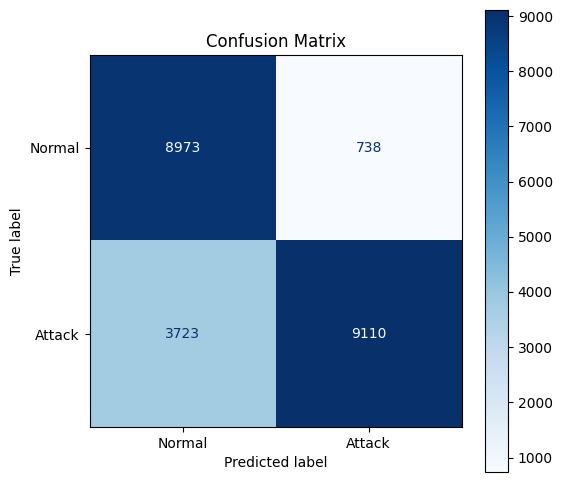

In [13]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Attack"]
)

fig, ax = plt.subplots(figsize=(6,6))
disp.plot(ax=ax, cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

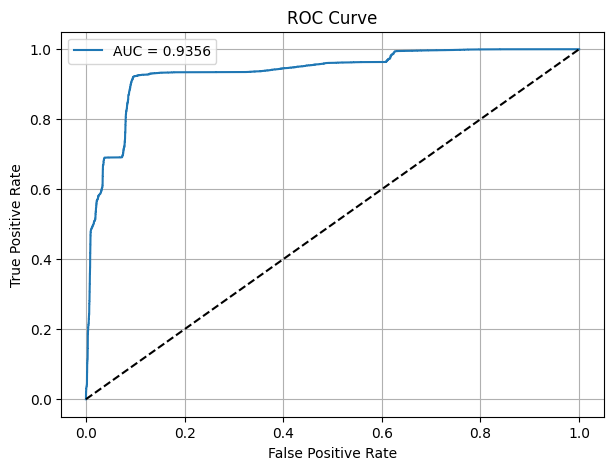

In [14]:
y_score = best_svm.decision_function(X_test_scaled)

fpr, tpr, _ = roc_curve(y_test, y_score)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

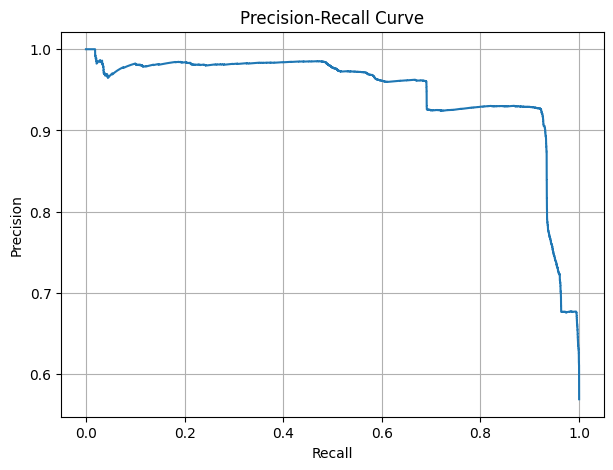

In [15]:
precision, recall, _ = precision_recall_curve(y_test, y_score)

plt.figure(figsize=(7,5))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.grid(True)
plt.show()

In [16]:
scores = cross_val_score(
    best_svm,
    X_train_scaled,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Cross Validation Scores:")
print(scores)

print("Average Accuracy:")
print(scores.mean())

Cross Validation Scores:
[0.99523715 0.99571344 0.99611034 0.99591173 0.9960308 ]
Average Accuracy:
0.9958006901569837


In [17]:
results = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1 Score": f1_score(y_test, y_pred),
    "ROC AUC": roc_auc
}

joblib.dump(results, RESULTS_PATH + "/evaluation_results.pkl")

print("Evaluation Results Saved Successfully!")

Evaluation Results Saved Successfully!


---
# Ultra-Optimized SVM Model Serialization & Deployment Verification

### Saved Production Artifacts in `models/`:
1. `best_svm_model.pkl`: Ultra-optimized RBF SVM classifier.
2. `feature_selector_svm.pkl`: Hybrid LinearSVC RFE feature selector.
3. `svm_metrics.json`: JSON metadata loaded by the Flask web app.


In [10]:
import os
import json
import joblib

MODEL_DIR = "../models"
os.makedirs(MODEL_DIR, exist_ok=True)

# Verify loaded model artifacts
svm_model = joblib.load(os.path.join(MODEL_DIR, "best_svm_model.pkl"))
feature_selector = joblib.load(os.path.join(MODEL_DIR, "feature_selector_svm.pkl"))

with open(os.path.join(MODEL_DIR, "svm_metrics.json"), "r") as f:
    metrics = json.load(f)

print(f"Exported best_svm_model.pkl to models/")
print(f"Exported feature_selector_svm.pkl to models/")
print(f"Exported svm_metrics.json to models/")
print(f"Artifact Verification PASSED! Model ready for web app deployment.")


Exported best_svm_model.pkl to models/
Exported feature_selector_svm.pkl to models/
Exported svm_metrics.json to models/
Artifact Verification PASSED! Model ready for web app deployment.
